# Martingale control variates

For the exact terminal payoff \(X=e^{-rT}g(S_T)\), subtract the discrete stochastic integral
\[
I_N=\sum_{n=0}^{N-1} h(t_n,S_{t_n})^\top \Delta B_n,\qquad
h(t,S)=e^{-rt}Z(t,S).
\]
The control sees the left-endpoint state. Each next Brownian increment has zero conditional mean, so \(\mathbb E[X-I_N]=\mathbb E[X]\) at every grid resolution. The grid changes the variance of the estimator.

The vanilla call and asymmetric five-asset geometric call have exact prices and spot deltas. The analytical control maps those deltas into independent Brownian coordinates. All grids use the same terminal payoff samples. Generate the two IID reports from the repository root.

```bash
python -m bsde_pricing martingale-control --case vanilla --output scratch/runs/martingale_vanilla.json
python -m bsde_pricing martingale-control --case geometric-five --output scratch/runs/martingale_geometric_five.json
```


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

cwd = Path.cwd()
root = cwd if (cwd / "bsde_pricing").is_dir() else cwd.parent
if not (root / "bsde_pricing").is_dir():
    raise RuntimeError("Open the notebook from the repository root or notebooks directory.")

runs = root / "scratch/runs"
report_names = ("martingale_vanilla.json", "martingale_geometric_five.json")
reports = [json.loads((runs / name).read_text(encoding="utf-8")) for name in report_names]


def show_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |",
             "| " + " | ".join("---" for _ in headers) + " |"]
    for row in rows:
        lines.append("| " + " | ".join(str(value) for value in row) + " |")
    display(Markdown("\n".join(lines)))


show_table(
    ("Case", "Exact price", "IID paths", "Seed", "Spawn key", "Grid intervals", "Runtime"),
    [(r["case"], f'{r["reference_call_price"]:.8f}', r["n_paths"], r["seed"], r["spawn_key"],
      [g["steps"] for g in r["grids"]], r["runtime"]["system"]) for r in reports],
)


| Case | Exact price | IID paths | Seed | Spawn key | Grid intervals | Runtime |
| --- | --- | --- | --- | --- | --- | --- |
| vanilla | 9.41340338 | 16384 | 2026 | [25, 1] | [4, 8, 16, 32, 64] | macOS-27.0.1-arm64-arm-64bit |
| geometric-five | 5.49471932 | 16384 | 2026 | [25, 5] | [4, 8, 16, 32, 64] | macOS-27.0.1-arm64-arm-64bit |

## Prices and sampling uncertainty

The zero control gives ordinary IID payoff Monte Carlo. The controlled standard error is the sample standard deviation of \(X-I_N\) divided by \(\sqrt M\). The variance reduction factor divides the zero-control sample variance by the controlled sample variance. The intervals are pointwise normal approximations. Reusing terminal paths makes the rows within a case dependent.

In [2]:
price_rows = []
for report in reports:
    controls = [("Zero", report["zero_control"], 1.0)]
    controls.extend((g["steps"], g["analytical_control"], g["variance_reduction_factor"])
                    for g in report["grids"])
    for steps, estimate, factor in controls:
        low, high = estimate["confidence_low"], estimate["confidence_high"]
        interval = "unavailable" if low is None else f"[{low:.6f}, {high:.6f}]"
        z = estimate["error_in_standard_errors"]
        price_rows.append((report["case"], steps, f'{estimate["estimate"]:.6f}',
                           f'{estimate["standard_error"]:.6f}', interval,
                           "unavailable" if z is None else f"{z:+.2f}",
                           "unavailable" if factor is None else f"{factor:.2f}"))

show_table(("Case", "Control intervals", "Price", "SE", "95% interval", "Error / SE", "Variance factor"),
           price_rows)


| Case | Control intervals | Price | SE | 95% interval | Error / SE | Variance factor |
| --- | --- | --- | --- | --- | --- | --- |
| vanilla | Zero | 9.435808 | 0.109651 | [9.220896, 9.650719] | +0.20 | 1.00 |
| vanilla | 4 | 9.423608 | 0.030638 | [9.363558, 9.483657] | +0.33 | 12.81 |
| vanilla | 8 | 9.408532 | 0.021856 | [9.365696, 9.451368] | -0.22 | 25.17 |
| vanilla | 16 | 9.407855 | 0.015747 | [9.376992, 9.438718] | -0.35 | 48.49 |
| vanilla | 32 | 9.406622 | 0.011248 | [9.384576, 9.428668] | -0.60 | 95.03 |
| vanilla | 64 | 9.417803 | 0.008000 | [9.402124, 9.433482] | +0.55 | 187.88 |
| geometric-five | Zero | 5.459020 | 0.067483 | [5.326756, 5.591284] | -0.53 | 1.00 |
| geometric-five | 4 | 5.517769 | 0.019937 | [5.478693, 5.556846] | +1.16 | 11.46 |
| geometric-five | 8 | 5.524709 | 0.014559 | [5.496175, 5.553243] | +2.06 | 21.49 |
| geometric-five | 16 | 5.509509 | 0.010317 | [5.489288, 5.529730] | +1.43 | 42.78 |
| geometric-five | 32 | 5.503657 | 0.007317 | [5.489316, 5.517998] | +1.22 | 85.06 |
| geometric-five | 64 | 5.500169 | 0.005240 | [5.489899, 5.510439] | +1.04 | 165.85 |

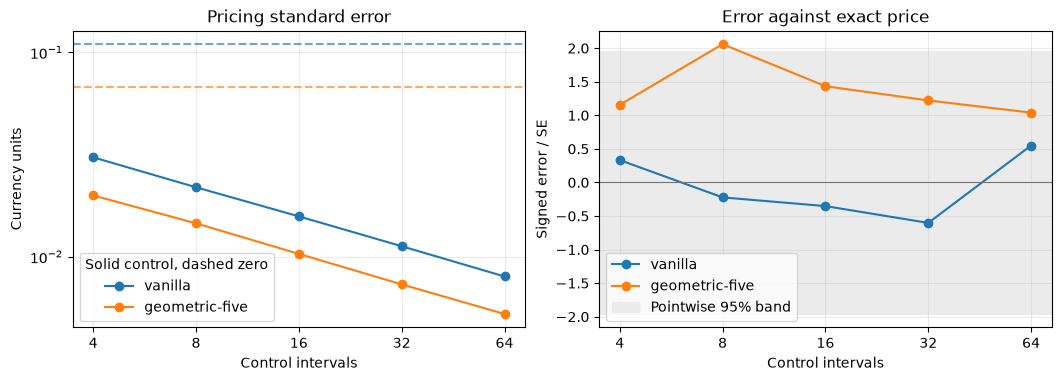

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7), constrained_layout=True)
for report, color in zip(reports, ("tab:blue", "tab:orange")):
    grids = report["grids"]
    steps = [g["steps"] for g in grids]
    axes[0].plot(steps, [g["analytical_control"]["standard_error"] for g in grids],
                 "o-", color=color, label=report["case"])
    axes[0].axhline(report["zero_control"]["standard_error"], color=color, ls="--", alpha=0.65)
    axes[1].plot(steps, [g["analytical_control"]["error_in_standard_errors"] for g in grids],
                 "o-", color=color, label=report["case"])

axes[0].set(title="Pricing standard error", yscale="log", ylabel="Currency units")
axes[0].legend(title="Solid control, dashed zero")
axes[1].axhspan(-1.96, 1.96, color="0.92", label="Pointwise 95% band")
axes[1].axhline(0, color="0.45", lw=0.8)
axes[1].set(title="Error against exact price", ylabel="Signed error / SE")
axes[1].legend()
for axis in axes:
    axis.set(xscale="log", xlabel="Control intervals")
    axis.set_xticks(steps, labels=steps)
    axis.minorticks_off()
    axis.grid(alpha=0.25)
plt.show()


## Martingale checks

Itô isometry gives \(\mathbb E[I_N^2]=\mathbb E[Q_N]\) for \(Q_N=\sum_n \|h(t_n,S_{t_n})\|^2\Delta t\). The uncertainty of the isometry gap uses paired path observations \(I_N^2-Q_N\). The stochastic-integral mean and the isometry gap each have target zero.

In [4]:
show_table(
    ("Case", "Intervals", "Mean integral", "Mean / SE", "Mean squared integral",
     "Mean control energy", "Isometry gap", "Gap / SE"),
    [(r["case"], g["steps"], f'{g["stochastic_integral"]["estimate"]:+.5f}',
      f'{g["stochastic_integral"]["mean_in_standard_errors"]:+.2f}',
      f'{g["mean_squared_integral"]:.5f}', f'{g["mean_integrated_squared_control"]:.5f}',
      f'{g["isometry_gap"]["estimate"]:+.5f}', f'{g["isometry_gap"]["mean_in_standard_errors"]:+.2f}')
     for r in reports for g in r["grids"]],
)


| Case | Intervals | Mean integral | Mean / SE | Mean squared integral | Mean control energy | Isometry gap | Gap / SE |
| --- | --- | --- | --- | --- | --- | --- | --- |
| vanilla | 4 | +0.01220 | +0.12 | 182.15574 | 184.06304 | -1.90730 | -0.71 |
| vanilla | 8 | +0.02728 | +0.25 | 189.25482 | 191.50480 | -2.24999 | -0.75 |
| vanilla | 16 | +0.02795 | +0.26 | 193.07029 | 195.26242 | -2.19213 | -0.70 |
| vanilla | 32 | +0.02919 | +0.27 | 194.97308 | 197.19585 | -2.22276 | -0.69 |
| vanilla | 64 | +0.01800 | +0.16 | 195.97239 | 198.21912 | -2.24672 | -0.69 |
| geometric-five | 4 | -0.05875 | -0.91 | 68.51836 | 69.59098 | -1.07262 | -1.03 |
| geometric-five | 8 | -0.06569 | -0.99 | 71.61595 | 72.74953 | -1.13358 | -0.99 |
| geometric-five | 16 | -0.05049 | -0.76 | 73.21950 | 74.41059 | -1.19109 | -0.99 |
| geometric-five | 32 | -0.04464 | -0.66 | 73.81774 | 75.24432 | -1.42658 | -1.16 |
| geometric-five | 64 | -0.04115 | -0.61 | 74.26509 | 75.67676 | -1.41167 | -1.14 |

The 64-interval analytical control substantially reduces sampling error in both cases. The geometric-basket estimate at eight intervals lies 2.06 standard errors above the exact price. The other pointwise intervals cover their references in this development run. The variance factors describe equal path counts. Computing the control requires intermediate states and deltas, so an equal-cost comparison is a separate experiment.